# Notebook 05: Dual-Tower Hybrid Mental Health Prediction

## Overview

This notebook implements an experimental dual-tower deep learning architecture for depression-related classification.

The architecture combines two information-processing branches:

- **Text tower:** Uses MentalRoBERTa to extract contextual representations from natural-language statements.
- **Structured-data tower:** Uses a multilayer perceptron (MLP) to process structured student information.
- **Fusion layer:** Combines the representations from both towers.
- **Classification head:** Produces a binary classification output.

The implementation explores how transformer-based text representations and structured numerical and categorical features can be combined within a single neural network.

**Important methodological note:** The student and Reddit datasets do not contain naturally matched person-level multimodal records. This experiment constructs synthetic pairs by matching records according to their existing labels. Consequently, its evaluation results should not be interpreted as evidence of real-world generalization or clinical validity.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Architecture II – Dual-Tower Hybrid Network Setup

import torch
from transformers import AutoTokenizer, AutoModel
import getpass
import os

# Secure interactive input for token if not already in environment
hf_token = os.environ.get("HF_TOKEN")
if not hf_token:
    hf_token = getpass.getpass("Enter your Hugging Face Access Token (or leave blank to use public roberta-base fallback): ").strip()
    if hf_token:
        os.environ["HF_TOKEN"] = hf_token
    else:
        hf_token = None

# Load gated model and tokenizer; fall back to 'roberta-base' if token is missing or invalid
try:
    if hf_token is None:
        raise ValueError("No token provided. Using fallback model.")
    print("Attempting to load gated model 'mental/mental-roberta-base'...")
    Model = AutoModel.from_pretrained("mental/mental-roberta-base", token=hf_token)
    tokenizer = AutoTokenizer.from_pretrained("mental/mental-roberta-base", token=hf_token)
    print("Successfully loaded 'mental/mental-roberta-base'!")
except Exception as e:
    print(f"Could not load gated model: {e}")
    print("Falling back to standard, publicly accessible 'roberta-base'...")
    Model = AutoModel.from_pretrained("roberta-base")
    tokenizer = AutoTokenizer.from_pretrained("roberta-base")
    print("Successfully loaded public 'roberta-base'!")

import pandas as pd
import numpy as np

# Define Google Drive dataset source filepaths
student_file = "/content/drive/MyDrive/mental_health_prdiction/cleaned_student_dataset.csv"
reddit_file =  "/content/drive/MyDrive/mental_health_prdiction/cleaned_reddit_dataset.csv"

# Load datasets and display initial previews
try:
    student_df = pd.read_csv(student_file)
    reddit_df = pd.read_csv(reddit_file)
    display(student_df.head())
    print("Columns:", student_df.columns.tolist())
except Exception as e:
    print(f"Error loading CSV datasets: {e}")
    print("Please ensure your Google Drive is mounted and the paths are correct.")

Enter your Hugging Face Access Token (or leave blank to use public roberta-base fallback): ··········
Could not load gated model: No token provided. Using fallback model.
Falling back to standard, publicly accessible 'roberta-base'...


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Successfully loaded public 'roberta-base'!


,Gender,Age,Academic Pressure,Work Pressure,CGPA,Sleep Duration,Dietary Habits,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression,serialized_text
0,Male,33,5.0,0.0,4.49,'5-6 hours',Healthy,3.0,1.0,0,1,"A 33-year-old Male student with CGPA 4.49, 5.0..."
1,Female,24,2.0,0.0,2.95,'5-6 hours',Moderate,3.0,2.0,1,0,"A 24-year-old Female student with CGPA 2.95, 2..."
2,Male,31,3.0,0.0,3.52,'Less than 5 hours',Healthy,9.0,1.0,1,0,"A 31-year-old Male student with CGPA 3.52, 3.0..."
3,Female,28,3.0,0.0,2.80,'7-8 hours',Moderate,4.0,5.0,1,1,"A 28-year-old Female student with CGPA 2.8, 3...."
4,Female,25,4.0,0.0,4.07,'5-6 hours',Moderate,1.0,1.0,0,0,"A 25-year-old Female student with CGPA 4.07, 4..."


Columns: ['Gender', 'Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Sleep Duration', 'Dietary Habits', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression', 'serialized_text']


## 1. Data Preparation and Splitting

The student and Reddit datasets are prepared separately. Invalid records and missing text entries are handled before splitting.

Each source dataset is divided into training and testing subsets using stratified sampling. Synthetic pairs are then constructed independently within each subset by matching records with the same binary label.

This prevents records from the original training partitions from being directly reused in the original testing partitions.

However, the resulting pairs do not represent genuine individuals whose structured information and written statements were collected together.

In [3]:
from sklearn.model_selection import train_test_split

# Rename the student target column to align with the joint schema
student_df = student_df.rename(columns={"Depression": "binary_label"})

# Remove serialized_text from the structured features.
# Reddit statements will provide the primary unstructured text input for this experiment.
student_df = student_df.drop(columns=["serialized_text"], errors="ignore")

# Define the structured student demographic/lifestyle features explicitly
student_feature_columns = [
    "Gender",
    "Age",
    "Academic Pressure",
    "Work Pressure",
    "CGPA",
    "Sleep Duration",
    "Dietary Habits",
    "Work/Study Hours",
    "Financial Stress",
    "Family History of Mental Illness"
]

# Check for any missing expected columns in the student dataframe
missing_student = [
    col for col in student_feature_columns + ["binary_label"]
    if col not in student_df.columns
]

if missing_student:
    raise ValueError(f"Missing student columns: {missing_student}")

# Ensure the Reddit dataset contains the text column and target labels
if not {"clean_text", "binary_label"}.issubset(reddit_df.columns):
    raise ValueError("Reddit dataset must contain clean_text and binary_label.")

# Ensure labels are represented as numeric elements safely
student_df["binary_label"] = pd.to_numeric(student_df["binary_label"], errors="coerce")
reddit_df["binary_label"] = pd.to_numeric(reddit_df["binary_label"], errors="coerce")

# Remove records with invalid or missing labels
student_df = student_df.dropna(subset=["binary_label"]).copy()
reddit_df = reddit_df.dropna(subset=["binary_label", "clean_text"]).copy()

# Validate binary constraints (0 or 1 labels only)
for name, dataframe in [("Student", student_df), ("Reddit", reddit_df)]:
    if not set(dataframe["binary_label"].unique()).issubset({0, 1}):
        raise ValueError(f"{name} dataset contains labels outside 0 and 1.")

# Remove empty or whitespace-only Reddit statements
reddit_df["clean_text"] = reddit_df["clean_text"].astype(str).str.strip()
reddit_df = reddit_df[reddit_df["clean_text"].ne("")].copy()

print("Student dataset:", student_df.shape)
print("Reddit dataset:", reddit_df.shape)

Student dataset: (27901, 11)
Reddit dataset: (42398, 2)


In [4]:
def one_to_many_join(reddit_data, student_data, random_state=42):
    """
    Generates synthetic pairings of text entries and structured features
    by matching items with identical class labels (late-fusion pair alignment).
    """
    combined_groups = []

    # Align pairs group-by-group based on target label values
    for label in [0, 1]:
        # Separate records by current target label
        reddit_group = reddit_data[reddit_data["binary_label"] == label].reset_index(drop=True)
        student_group = student_data[student_data["binary_label"] == label].reset_index(drop=True)

        if reddit_group.empty or student_group.empty:
            raise ValueError(f"Insufficient records for class {label}.")

        # Sample student records with replacement to match text collection size
        student_sampled = student_group.sample(
            n=len(reddit_group),
            replace=True,
            random_state=random_state + label
        ).reset_index(drop=True)

        # Align the extracted text and structured features
        text_data = reddit_group[["clean_text"]].reset_index(drop=True)
        structured_data = student_sampled[student_feature_columns].reset_index(drop=True)

        # Merge text with its paired structured features
        paired_data = pd.concat([text_data, structured_data], axis=1)
        paired_data["target"] = label
        combined_groups.append(paired_data)

    # Concatenate label subgroups and shuffle row order
    final_data = pd.concat(combined_groups, ignore_index=True)
    final_data = final_data.sample(frac=1, random_state=random_state).reset_index(drop=True)

    return final_data

In [5]:
from sklearn.model_selection import train_test_split

# 1. Split the unstructured Reddit dataset into 80% train and 20% test partitions
# Stratification is used to preserve the target class balance in both subsets
reddit_train, reddit_test = train_test_split(
    reddit_df,
    test_size=0.2,
    random_state=42,
    stratify=reddit_df["binary_label"]
)

# 2. Split the structured Student dataset into 80% train and 20% test partitions
# We use the same random_state and stratify on the student labels to keep consistency
student_train, student_test = train_test_split(
    student_df,
    test_size=0.2,
    random_state=42,
    stratify=student_df["binary_label"]
)

# 3. Construct synthetic training pairs purely from the training splits
# This enforces strict separation and prevents leakage from the testing sets
train_df = one_to_many_join(
    reddit_train,
    student_train,
    random_state=42
)

# 4. Construct synthetic testing pairs purely from the testing splits
test_df = one_to_many_join(
    reddit_test,
    student_test,
    random_state=43
)

# Display the final datasets sizes and target class distributions
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

print("\nTraining label distribution:")
print(train_df["target"].value_counts())

print("\nTesting label distribution:")
print(test_df["target"].value_counts())

train_df.head()

Training dataset: (33918, 12)
Testing dataset: (8480, 12)

Training label distribution:
target
1    20844
0    13074
Name: count, dtype: int64

Testing label distribution:
target
1    5211
0    3269
Name: count, dtype: int64


,clean_text,Gender,Age,Academic Pressure,Work Pressure,CGPA,Sleep Duration,Dietary Habits,Work/Study Hours,Financial Stress,Family History of Mental Illness,target
0,i just turned 18 two months ago. it was never ...,Female,23,4.0,0.0,4.40,'5-6 hours',Healthy,8.0,4.0,1,1
1,i have the flu,Male,28,2.0,0.0,4.07,'7-8 hours',Healthy,0.0,1.0,0,0
2,i am the kind of person that craves touch and ...,Female,19,2.0,0.0,2.72,'More than 8 hours',Unhealthy,12.0,4.0,0,1
3,how do i stop this feeling to give up on life ...,Male,20,5.0,0.0,4.02,'7-8 hours',Moderate,6.0,5.0,1,1
4,i had a busy morning.,Male,21,1.0,0.0,3.14,'Less than 5 hours',Healthy,12.0,4.0,1,0


In [6]:
import numpy as np
import pandas as pd

# Identify Categorical Features for One-Hot Encoding
categorical_features = [
    "Gender",
    "Sleep Duration",
    "Dietary Habits"
]

# Identify Numerical Features for Scaling and Imputation
numerical_features = [
    "Age",
    "Academic Pressure",
    "Work Pressure",
    "CGPA",
    "Work/Study Hours",
    "Financial Stress",
    "Family History of Mental Illness"
]

# Convert all numeric targets and feature types safely
for col in numerical_features:
    train_df[col] = pd.to_numeric(train_df[col], errors="coerce")
    test_df[col] = pd.to_numeric(test_df[col], errors="coerce")

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Preprocessing pipeline for Numerical Features: Impute median then standard scale
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing pipeline for Categorical Features: Most frequent imputation then one-hot encode
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Assemble unified preprocessing pipeline for downstream structured processing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    sparse_threshold=0.0
)

In [8]:
# Fit on training set and transform both partitions
X_train_structured = preprocessor.fit_transform(train_df[numerical_features + categorical_features])

X_test_structured = preprocessor.transform(test_df[numerical_features + categorical_features])

# Format outputs as numpy arrays for training loaders
y_train = train_df["target"].to_numpy(dtype=np.int64)
y_test = test_df["target"].to_numpy(dtype=np.int64)

print("Training features:", X_train_structured.shape)
print("Testing features:", X_test_structured.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (33918, 18)
Testing features: (8480, 18)
Training labels: (33918,)
Testing labels: (8480,)


## 2. Dual-Tower Architecture

The model contains two parallel processing branches.

### Text tower

MentalRoBERTa processes natural-language statements and extracts contextual text representations.

### Structured-data tower

A multilayer perceptron processes the preprocessed numerical and categorical student features.

### Feature fusion

The two representations are concatenated and passed through a classification network to produce two output logits.

In [9]:
import torch
import torch.nn as nn

class DualTowerModel(nn.Module):
    # A PyTorch deep neural network merging text and tabular features using two branches"

    def __init__(self, text_model, num_student_features):
        super(DualTowerModel, self).__init__()

        # Branch 1: Pretrained contextual language representation
        self.text_model = text_model
        hidden_size = text_model.config.hidden_size

        # Branch 2: Multi-Layer Perceptron for structured tabular processing
        self.structured_tower = nn.Sequential(
            nn.Linear(num_student_features, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        # Fusion Layer: Concatenate both sets of embedding outputs and classify
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size + 32, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 2)
        )

    def forward(self, input_ids, attention_mask, stats):
        # 1. Fetch contextual textual pool embeddings (CLS token)
        text_output = self.text_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        text_features = text_output.last_hidden_state[:, 0, :]

        # 2. Map structural features down to 32 dimensions
        structured_features = self.structured_tower(stats)

        # 3. Join textual and structural features along dimension 1
        combined_features = torch.cat(
            (text_features, structured_features),
            dim=1
        )

        # 4. Predict binary class logits
        output = self.classifier(combined_features)
        return output

In [10]:
import torch
from torch.utils.data import Dataset

class HybridDataset(Dataset):
    ""
    Custom Dataset structure packaging both aligned textual and structural features.
    ""
    def __init__(self, texts, structured_features, labels, tokenizer):
        self.texts = texts.reset_index(drop=True)
        self.structured_features = torch.tensor(
            structured_features,
            dtype=torch.float32
        )
        self.labels = torch.tensor(labels, dtype=torch.long)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        text = str(self.texts.iloc[index])

        # Tokenize text on-the-fly into tensor keys
        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0),
            "stats": self.structured_features[index],
            "labels": self.labels[index]
        }

In [11]:
from torch.utils.data import DataLoader

# Define the PyTorch Dataset containers
train_dataset = HybridDataset(
    train_df["clean_text"],
    X_train_structured,
    y_train,
    tokenizer
)

test_dataset = HybridDataset(
    test_df["clean_text"],
    X_test_structured,
    y_test,
    tokenizer
)

# Define PyTorch loaders to batch the training/testing processes
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

## 3. Model Training

The model is trained using:

- Optimizer: AdamW
- Learning rate: 0.00002
- Loss function: CrossEntropyLoss
- Batch size: 16
- Training epochs: 3
- Maximum token length: 128

MentalRoBERTa is fine-tuned jointly with the structured-data tower and classification head.

In [12]:
import torch
import torch.nn as nn
from torch.optim import AdamW

# Dynamically select GPU accelerator if available; fallback to CPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Using device:", device)

# Initialize the Dual-Tower Hybrid Model
model = DualTowerModel(
    text_model=Model,
    num_student_features=X_train_structured.shape[1]
).to(device)

# Configure CrossEntropy criterion and learning parameters
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

print("Model initialized successfully.")
print("Number of structured features:", X_train_structured.shape[1])

Using device: cuda
Model initialized successfully.
Number of structured features: 18


In [15]:
def train_model(model, train_loader, optimizer, criterion, device, epochs=3):
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        correct = 0
        total = 0

        print(f"\n--- Starting Epoch {epoch + 1}/{epochs} ---")
        for batch_idx, batch in enumerate(train_loader):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            stats = batch["stats"].to(device)
            labels = batch["labels"].to(device)

            optimizer.zero_grad()

            outputs = model(
                input_ids,
                attention_mask,
                stats
            )

            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            predictions = torch.argmax(outputs, dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            # Print real-time progress every 100 batches
            if (batch_idx + 1) % 100 == 0 or (batch_idx + 1) == len(train_loader):
                running_loss = total_loss / (batch_idx + 1)
                running_acc = correct / total
                print(
                    f"Batch [{batch_idx + 1}/{len(train_loader)}] | "
                    f"Running Loss: {running_loss:.4f} | "
                    f"Running Acc: {running_acc:.4f}"
                )

        average_loss = total_loss / len(train_loader)
        accuracy = correct / total
        print(f"Epoch [{epoch + 1}/{epochs}] Completed - Avg Loss: {average_loss:.4f} - Accuracy: {accuracy:.4f}")

In [16]:
# Start the joint fine-tuning process of the Dual-Tower architecture
# We train for 3 epochs using the AdamW optimizer with a learning rate of 2e-5
train_model(
    model=model,                  # The hybrid neural network (RoBERTa + MLP structured branch)
    train_loader=train_loader,    # PyTorch DataLoader providing balanced batches of synthetic pairs
    optimizer=optimizer,          # AdamW optimizer managing parameter updates for both towers
    criterion=criterion,          # CrossEntropyLoss to compute gradients on binary classification targets
    device=device,                # Selected hardware accelerator (ideally CUDA GPU)
    epochs=3                      # Total passes over the complete training dataset
)


--- Starting Epoch 1/3 ---
Batch [100/2120] | Running Loss: 0.1129 | Running Acc: 0.9575
Batch [200/2120] | Running Loss: 0.0958 | Running Acc: 0.9650
Batch [300/2120] | Running Loss: 0.0893 | Running Acc: 0.9673
Batch [400/2120] | Running Loss: 0.0864 | Running Acc: 0.9694
Batch [500/2120] | Running Loss: 0.0867 | Running Acc: 0.9698
Batch [600/2120] | Running Loss: 0.0882 | Running Acc: 0.9685
Batch [700/2120] | Running Loss: 0.0867 | Running Acc: 0.9696
Batch [800/2120] | Running Loss: 0.0842 | Running Acc: 0.9710
Batch [900/2120] | Running Loss: 0.0838 | Running Acc: 0.9710
Batch [1000/2120] | Running Loss: 0.0833 | Running Acc: 0.9713
Batch [1100/2120] | Running Loss: 0.0828 | Running Acc: 0.9714
Batch [1200/2120] | Running Loss: 0.0818 | Running Acc: 0.9717
Batch [1300/2120] | Running Loss: 0.0795 | Running Acc: 0.9724
Batch [1400/2120] | Running Loss: 0.0775 | Running Acc: 0.9731
Batch [1500/2120] | Running Loss: 0.0766 | Running Acc: 0.9736
Batch [1600/2120] | Running Loss: 0.

## 4. Model Evaluation

The trained model is evaluated using a held-out synthetic test set.

Evaluation metrics include:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

These metrics describe performance on the constructed synthetic test pairs. They should not be interpreted as validated performance on real individuals.

In [17]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np

def evaluate_model(model, test_loader, device):

    # Evaluates accuracy and classification metrics across the test dataset.

    model.eval()
    all_predictions = []
    all_labels = []

    # Run evaluation without computing model gradient backpropagation
    with torch.no_grad():
        for batch in test_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            stats = batch["stats"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids,
                attention_mask,
                stats
            )

            predictions = torch.argmax(outputs, dim=1)
            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # Log classification performance metrics
    print("Test Accuracy:", accuracy_score(all_labels, all_predictions))
    print("\nClassification Report:")
    print(classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=["Non-depression label", "Depression-related label"],
        zero_division=0
    ))

    print("\nConfusion Matrix:")
    print(confusion_matrix(
        all_labels,
        all_predictions,
        labels=[0, 1]
    ))

    return all_labels, all_predictions

In [18]:
# Execute the model evaluation using the test loader
# This returns the ground-truth targets (y_true) and predictions (y_pred)
y_true, y_pred = evaluate_model(
    model=model,
    test_loader=test_loader,
    device=device
)

Test Accuracy: 0.9832547169811321

Classification Report:
                          precision    recall  f1-score   support

    Non-depression label       0.98      0.98      0.98      3269
Depression-related label       0.99      0.99      0.99      5211

                accuracy                           0.98      8480
               macro avg       0.98      0.98      0.98      8480
            weighted avg       0.98      0.98      0.98      8480


Confusion Matrix:
[[3203   66]
 [  76 5135]]


In [19]:
import os
import joblib
import torch

# 1. Define the persistent output directory inside the mounted Google Drive
MODEL_DIR = "/content/drive/MyDrive/mental_health_prediction/models"

# 2. Create the directories if they do not already exist
os.makedirs(MODEL_DIR, exist_ok=True)

# 3. Serialize and save the PyTorch model state dictionary containing all trained weights
torch.save(
    model.state_dict(),
    os.path.join(MODEL_DIR, "hybrid_model.pth")
)

print("Model weights saved successfully.")

Model weights saved successfully.


In [20]:
# 1. Serialize and save the Scikit-Learn ColumnTransformer preprocessing pipeline
# This ensures structured testing samples can be transformed identically during future inference
joblib.dump(
    preprocessor,
    os.path.join(MODEL_DIR, "structured_preprocessor.pkl")
)

# 2. Save the vocabulary configuration and weights of the trained text tokenizer
tokenizer.save_pretrained(
    os.path.join(MODEL_DIR, "tokenizer")
)

print("Preprocessor and tokenizer saved successfully.")

Preprocessor and tokenizer saved successfully.


In [21]:
# Define static configuration parameters for reconstructing the Dual-Tower pipeline
model_config = {
    "base_model": "mental/mental-roberta-base",
    "hidden_size": Model.config.hidden_size,
    "structured_features": numerical_features + categorical_features,
    "num_structured_features": X_train_structured.shape[1],
    "max_length": 128,
    "num_classes": 2,
    "class_mapping": {
        "0": "Non-depression label",
        "1": "Depression-related label"
    }
}

# Save the configuration dictionary as a joblib pickle file
joblib.dump(
    model_config,
    os.path.join(MODEL_DIR, "model_config.pkl")
)

print("Model configuration saved successfully.")

Model configuration saved successfully.


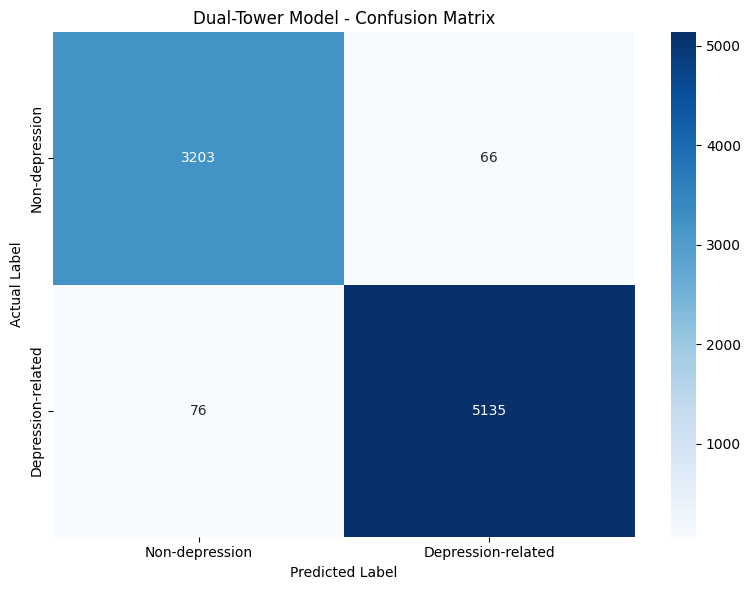

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Compute the raw values of the confusion matrix using true vs predicted target labels
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

# 2. Initialize a Matplotlib figure for visualization
plt.figure(figsize=(8, 6))

# 3. Use Seaborn to plot a heatmap representing actual vs predicted alignments
sns.heatmap(
    cm,
    annot=True,               # Display numeric counts in individual cells
    fmt="d",                  # Format counts as raw integers
    cmap="Blues",             # Color scheme mapping
    xticklabels=["Non-depression", "Depression-related"],
    yticklabels=["Non-depression", "Depression-related"]
)

# 4. Set axes labels, titles, and layout formatting
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Dual-Tower Model - Confusion Matrix")
plt.tight_layout()

# 5. Save the generated confusion matrix figure to Google Drive before presenting
plt.savefig(
    os.path.join(MODEL_DIR, "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

# 6. Display the final plot output
plt.show()

Training accuracy: 99.13%



Test accuracy: 98.33%



Training loss: 0.0271



Test samples: 8,480

These results are obtained from synthetically paired records constructed using existing class labels. They demonstrate performance on the experimental dataset and should not be interpreted as evidence of real-world predictive performance or clinical validity.